# Advanced Data Preparation with Python (Car Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped car data from AutoScout24. It is an exercise: complete the empty code cells by applying the steps from the apartment data notebook. 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [1]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/python_data_preparation


## Importing data

In [2]:
# Import data from csv to pandas dataframe named 'df'
df = pd.read_csv('./Data/autoscout24_data.csv', sep=";", encoding='utf-8')

# Change the column names to lowercase
df.columns = df.columns.str.lower()

# Display the first 5 rows of the dataframe
df.head()


,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09


## Count number of rows and columns in the data frame

In [3]:
# Count number of rows and columns in the data frame

# Dimension (rows, columns)
print('Dimension:', df.shape)

# Number of rows
print('Number of rows:', df.shape[0])

# Number of columns
print('Number of columns:', df.shape[1])


Dimension: (3980, 19)
Number of rows: 3980
Number of columns: 19


## Get data types (raw-format from web scraper)

In [4]:
# Get data types of each column
# Get data types (note that in pandas, a string is referred to as 'object')
df.dtypes


url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
dtype: object

## Extract information from raw data using regular expressions (regex)

### Extract numerical values from mileage_raw

In [5]:
# First look at the data for the exercise
df[['mileage_raw', 'hp_raw', 'price_raw']].head(10)

,mileage_raw,hp_raw,price_raw
0,75'000 km,245 PS,CHF 22'500.–
1,46'655 km,184 PS,CHF 23'749.–
2,138'955 km,306 PS,CHF 18'500.–
3,43'000 km,360 PS,CHF 36'000.–
4,43'300 km,252 PS,CHF 48'500.–
5,109'000 km,163 PS,CHF 12'000.–
6,156'000 km,272 PS,CHF 8'000.–
7,71'400 km,180 PS,CHF 10'500.–
8,18'000 km,521 PS,CHF 143'500.–
9,110'000 km,125 PS,CHF 19'800.–


In [6]:
# Extract numerical values from mileage_raw
mileage = []
for i in df['mileage_raw']:
    d1 = re.findall(r"(\d{1,3}(?:'\d{3})*)\s*km", i)
    try:
        d2 = d1[0].strip().replace("'", "")
    except:
        d2 = None
    mileage.append(d2)

# Save as new variable in the pandas data frame
df['mileage'] = pd.Series(mileage, dtype="float64")

# Show first records of data frame
df[['mileage_raw', 'mileage']].head()

,mileage_raw,mileage
0,75'000 km,75000.0
1,46'655 km,46655.0
2,138'955 km,138955.0
3,43'000 km,43000.0
4,43'300 km,43300.0


### Extract numerical values from hp_raw

In [7]:
# Extract numerical values from hp_raw
hp = []
for i in df['hp_raw']:
    d1 = re.findall(r"(\d+)\s*PS", i)
    try:
        d2 = d1[0].strip()
    except:
        d2 = None
    hp.append(d2)

# Save as new variable in the pandas data frame
df['hp'] = pd.Series(hp, dtype="float64")

# Show first records of data frame
df[['hp_raw', 'hp']].head()

,hp_raw,hp
0,245 PS,245.0
1,184 PS,184.0
2,306 PS,306.0
3,360 PS,360.0
4,252 PS,252.0


### Extract numerical values from price_raw

In [8]:
# Extract numerical values from price_raw -> CHF 22'500.–
price = []
for i in df['price_raw']:
    d1 = re.findall(r"CHF\s*(\d{1,3}(?:'\d{3})*)\.–", i)
    try:
        d2 = d1[0].strip().replace("'", "")
    except:
        d2 = None
    price.append(d2)

# Save as new variable in the pandas data frame
df['price'] = pd.Series(price, dtype="float64")

# Show first records of data frame
df[['price_raw', 'price']].head()

,price_raw,price
0,CHF 22'500.–,22500.0
1,CHF 23'749.–,23749.0
2,CHF 18'500.–,18500.0
3,CHF 36'000.–,36000.0
4,CHF 48'500.–,48500.0


### Get data types of all variables, including the new once

In [9]:
# Get data types of all variables
df.dtypes

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
mileage                   float64
hp                        float64
price                     float64
dtype: object

## Count and remove missing values

In [10]:
# Count and remove missing values
print(f"Number of missing values: {pd.isna(df).sum().sum()}")

# Reset the index of the dataframe
df = df.dropna().reset_index(drop=True)

Number of missing values: 23


## Count and remove duplicated values

In [11]:
# Count and remove duplicates
print(f"Number of duplicated values: {df[['offer_id']].duplicated().sum()}")

# Reset the index of the dataframe
df = df.drop_duplicates().reset_index(drop=True)
print('\nDimension:', df.shape)

Number of duplicated values: 0

Dimension: (3971, 22)


## Use string manipulation methods to create additional variables from the car type

### Change strings in 'type' to uppercase

In [12]:
# Change strings in 'type' to uppercase and remove leading and trailing whitespaces
df['type'] = df['type'].str.upper().str.strip()


# Display variable 'type'
print('Type:\n', df['type'].head(5), '\n')

Type:
 0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str 



### Calculate length of strings in 'type'

In [13]:
# Calculate length of strings in 'type'
df['type_len'] = df['type'].str.len()

# Display variables 'type' and 'type_len'
# print(df['type'].head(10))
# print(df['type_len'].head(10))

df[['type','type_len']].head(10) # see both variables next to each other

,type,type_len
0,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,54
1,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),43
2,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,59
3,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,59
4,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,61
5,MERCEDES-BENZ SLK 200 KOMPRESSOR (CABRIOLET),44
6,MERCEDES-BENZ C 350 ELÉGANCE SPORT EDITION 4MA...,67
7,SEAT IBIZA SC 1.4 TSI CUPRA DSG (KLEINWAGEN),44
8,PORSCHE 911 TURBO CABRIO PDK (CABRIOLET),40
9,VW GOLF 1.4 TSI COMFORTLINE (LIMOUSINE),39


### Create binary (0/1) variable 'luxury_car'

In [14]:
# look at the data first
display(df['type'].sample(20))

# look at alle the brands
print(df['type'].str.split().str[0].value_counts().to_string())

# Create a pattern which can be used to search the variable 'type'
pattern = 'BENTLEY|ASTON|PORSCHE|MASERATI|FERRARI|JAGUAR|CAMARO|MCLAREN|LAMBORGHINI|HUMMER|LOTUS|ROLLS-ROYCE'

# Create new variable 'luxurious' as binary dummy (0/1) variable
df['luxury_car'] = df['type'].str.contains(pat = pattern).astype(int)
print(df['luxury_car'].sum())

# Show values
df[['type','type_len','price_raw','luxury_car']].loc[df['luxury_car'] == 1]

202     MERCEDES-BENZ GLA 45 AMG 4MATIC 7G-DCT (SUV / ...
770     MERCEDES-BENZ C 250 BLUETEC AMG LINE 4MATIC 7G...
1447    BMW X1 XDRIVE 20I STEPTRONIC (SUV / GELÄNDEWAGEN)
942                         PORSCHE 911 CARRERA 4 (COUPÉ)
2114     CHRYSLER SEBRING 2.7 V6 LIMITED (LX) (LIMOUSINE)
1175         VW POLO 1.2 TSI BMT COMFORTLINE (KLEINWAGEN)
3663                HONDA CIVIC 1.5I LS VTEC (KLEINWAGEN)
3589                            LOTUS EXIGE S (CABRIOLET)
3543                      BMW 635D STEPTRONIC (CABRIOLET)
538     AUDI Q5 2.0 TDI QUATTRO S-TRONIC (SUV / GELÄND...
931     AUDI A5 SPORTBACK 2.0 TDI QUATTRO S-TRONIC (LI...
1061    VW PASSAT VARIANT 2.0 TDI BMT HIGHLINE DSG (KO...
765                   HYUNDAI I30 1.6 GDI GO! (LIMOUSINE)
1000           VW EOS 2.0 TSI WHITE NIGHT DSG (CABRIOLET)
233     RENAULT KADJAR 1.3 16V TURBO BLACK EDITION EDC...
1307      FORD MUSTANG FASTBACK 5.0 V8 GT AUTOMAT (COUPÉ)
1689    LAND ROVER RANGE ROVER EVOQUE 2.0 SI4 PRESTIGE...
1013         P

type
BMW              546
AUDI             505
MERCEDES-BENZ    491
VW               386
PORSCHE          214
SKODA            114
FORD             105
LAND             104
FIAT              94
SEAT              83
VOLVO             83
MINI              83
OPEL              81
RENAULT           75
TOYOTA            71
PEUGEOT           61
MAZDA             59
ALFA              55
TESLA             50
JAGUAR            47
HYUNDAI           47
SUBARU            45
NISSAN            45
CHEVROLET         45
CITROEN           40
JEEP              35
HONDA             35
MITSUBISHI        29
SMART             26
ASTON             25
SUZUKI            22
MASERATI          22
KIA               21
DODGE             20
DACIA             19
SAAB              19
FERRARI           18
DS                15
LEXUS             13
CHRYSLER          12
CADILLAC          12
MG                10
BENTLEY            8
LAMBORGHINI        7
INFINITI           6
HUMMER             6
LANCIA             6
LOTUS   

,type,type_len,price_raw,luxury_car
8,PORSCHE 911 TURBO CABRIO PDK (CABRIOLET),40,CHF 143'500.–,1
23,JAGUAR F-PACE 2.0D PRESTIGE AWD AUTOMATIK (SUV...,62,CHF 29'999.–,1
26,FERRARI 348 TS (CABRIOLET),26,CHF 54'900.–,1
57,PORSCHE 911 SC (COUPÉ),22,CHF 71'900.–,1
64,PORSCHE 911 CARRERA 4S PDK (COUPÉ),34,CHF 122'000.–,1
...,...,...,...,...
3934,FERRARI 458 ITALIA 4.5 V8 (COUPÉ),33,CHF 140'000.–,1
3952,JAGUAR XJ 3.2 V8 EXECUTIVE (LIMOUSINE),38,CHF 8'900.–,1
3958,PORSCHE 911 TURBO (S) CABRIO (CABRIOLET),40,CHF 69'911.–,1
3964,BENTLEY ARNAGE RED LABEL (LIMOUSINE),36,CHF 38'500.–,1


### Create variable 'price_per_hp'

In [15]:
df.dtypes

# Create the new variable
df['price_per_hp'] = round(df['price'] / df['hp'], 2)

# oder besser df['price_per_hp'] = (df['price'] / df['hp']).round(2) liefert dasselbe Ergebnis

# Show values
df[['type','type_len','mileage','price','hp','price_per_hp']]

,type,type_len,mileage,price,hp,price_per_hp
0,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,54,75000.0,22500.0,245.0,91.84
1,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),43,46655.0,23749.0,184.0,129.07
2,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,59,138955.0,18500.0,306.0,60.46
3,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,59,43000.0,36000.0,360.0,100.00
4,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,61,43300.0,48500.0,252.0,192.46
...,...,...,...,...,...,...
3966,FERRARI F360 SPIDER (CABRIOLET),31,78000.0,58400.0,400.0,146.00
3967,MERCEDES-BENZ SL 500 560 SL (CABRIOLET),39,315000.0,15900.0,232.0,68.53
3968,MERCEDES-BENZ CL 63 AMG 7G-TRONIC (COUPÉ),41,85000.0,42000.0,525.0,80.00
3969,BMW 328I CABRIO (CABRIOLET),27,188920.0,9980.0,193.0,51.71


### Include current datetime as time stamp

In [16]:
# Get and format datetime
df['datetime'] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
# Show values
df[['type','type_len','mileage','price','hp','price_per_hp','datetime']]

,type,type_len,mileage,price,hp,price_per_hp,datetime
0,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,54,75000.0,22500.0,245.0,91.84,2026-11-08 17:01:04
1,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),43,46655.0,23749.0,184.0,129.07,2026-11-08 17:01:04
2,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,59,138955.0,18500.0,306.0,60.46,2026-11-08 17:01:04
3,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,59,43000.0,36000.0,360.0,100.00,2026-11-08 17:01:04
4,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,61,43300.0,48500.0,252.0,192.46,2026-11-08 17:01:04
...,...,...,...,...,...,...,...
3966,FERRARI F360 SPIDER (CABRIOLET),31,78000.0,58400.0,400.0,146.00,2026-11-08 17:01:04
3967,MERCEDES-BENZ SL 500 560 SL (CABRIOLET),39,315000.0,15900.0,232.0,68.53,2026-11-08 17:01:04
3968,MERCEDES-BENZ CL 63 AMG 7G-TRONIC (COUPÉ),41,85000.0,42000.0,525.0,80.00,2026-11-08 17:01:04
3969,BMW 328I CABRIO (CABRIOLET),27,188920.0,9980.0,193.0,51.71,2026-11-08 17:01:04


## Discretization of numerical data

In [17]:
# Discretization of the variable 'price_per_hp'
df['price_per_hp_cat'] = pd.qcut(df['price_per_hp'], 
                               q = 5, 
                                labels = ['very cheap', 
                                            'cheap', 
                                            'normal', 
                                            'expensive', 
                                            'very expensive'])

# Show unique values
display(df['price_per_hp_cat'].unique())
display(df['price_per_hp_cat'].value_counts().sort_index())



display(df[['type', 'price', 'hp', 'price_per_hp']].loc[df['price_per_hp_cat'] == 'very expensive'])

['normal', 'expensive', 'cheap', 'very expensive', 'very cheap']
Categories (5, str): ['very cheap' < 'cheap' < 'normal' < 'expensive' < 'very expensive']

price_per_hp_cat
very cheap        795
cheap             795
normal            793
expensive         794
very expensive    794
Name: count, dtype: int64

,type,price,hp,price_per_hp
4,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,48500.0,252.0,192.46
8,PORSCHE 911 TURBO CABRIO PDK (CABRIOLET),143500.0,521.0,275.43
15,BMW M4 CABRIOLET DKG (CABRIOLET),77800.0,431.0,180.51
23,JAGUAR F-PACE 2.0D PRESTIGE AWD AUTOMATIK (SUV...,29999.0,180.0,166.66
26,FERRARI 348 TS (CABRIOLET),54900.0,286.0,191.96
...,...,...,...,...
3954,MORGAN PLUS 4 2.0 4 PLACE SPEZIAL (CABRIOLET),82900.0,154.0,538.31
3955,MORGAN PLUS 4 2.0 SWISS PACK (CABRIOLET),53900.0,156.0,345.51
3956,MORGAN PLUS 8 (CABRIOLET),60000.0,150.0,400.00
3957,MORGAN PLUS 8 4.6 (CABRIOLET),72500.0,220.0,329.55


## One Hot Encoding

In [18]:
# One Hot Encoding of the variable 'price_per_hp_cat'
try:
    df = pd.get_dummies(df, 
                        columns=['price_per_hp_cat'], 
                        drop_first=False)
except:
    print("Dummy variables already exist")

# Convert boolean values to integers (0 and 1)
df[df.filter(like='price_per_hp_cat').columns] = df.filter(like='price_per_hp_cat').astype(int)

# Show values of the new dummy variables
df.filter(like='price_per_hp_cat').head()

,price_per_hp_cat_very cheap,price_per_hp_cat_cheap,price_per_hp_cat_normal,price_per_hp_cat_expensive,price_per_hp_cat_very expensive
0,0,0,1,0,0
1,0,0,0,1,0
2,0,1,0,0,0
3,0,0,1,0,0
4,0,0,0,0,1


## Scaling

### Min-Max Scaling

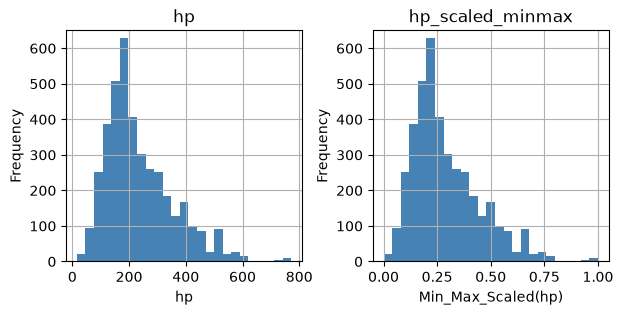

In [19]:
# Min-Max scaling of the variable 'hp'
df['hp_scaled_minmax'] = (df['hp'] - df['hp'].min()) / (df['hp'].max() - df['hp'].min())

# Histogram of the variable 'hp' and 'hp_scaled'
ax = df[['hp', 'hp_scaled_minmax']].hist(bins=25, 
                                      figsize=(7, 3), 
                                      color='steelblue')
                                      
# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['hp', 'Min_Max_Scaled(hp)']):
    axis.set_ylim(0, 650)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

# Min-Max Scling works well with hp because there are no strong outliers, link in the apartment data.

### Max-Absolute Scaling

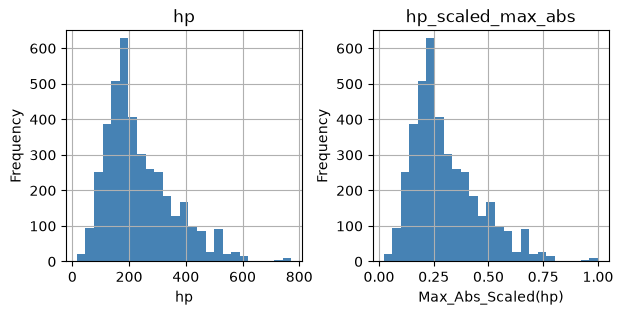

hp                   16.000000
hp_scaled_minmax      0.000000
hp_scaled_max_abs     0.020725
dtype: float64

In [20]:
# Max-Absolute scaling of the variable 'hp'
df['hp_scaled_max_abs'] = df['hp'] / df['hp'].abs().max()

# Histogram of the variable 'hp' and 'hp_scaled_max_abs'
ax = df[['hp', 'hp_scaled_max_abs']].hist(bins=25, 
                                              figsize=(7, 3), 
                                              color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['hp', 'Max_Abs_Scaled(hp)']):
    axis.set_ylim(0, 650)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()
display(df[['hp', 'hp_scaled_minmax', 'hp_scaled_max_abs']].min())

### Robust Scaling

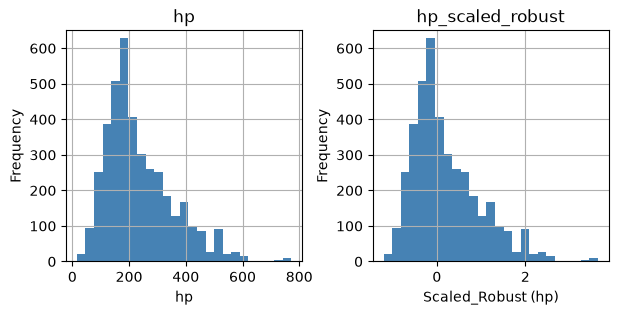

hp                   16.000000
hp_scaled_minmax      0.000000
hp_scaled_max_abs     0.020725
hp_scaled_robust     -1.205128
dtype: float64

hp                   772.000000
hp_scaled_minmax       1.000000
hp_scaled_max_abs      1.000000
hp_scaled_robust       3.641026
dtype: float64

In [21]:
# Robust scaling of the variable 'hp'
df['hp_scaled_robust'] = (df['hp'] - df['hp'].median()) / \
                           (df['hp'].quantile(0.75) \
                           - df['hp'].quantile(0.25))

# Histogram of the variable 'hp' and 'hp_scaled_robust'
ax = df[['hp', 'hp_scaled_robust']].hist(bins=25, 
                                             figsize=(7, 3), 
                                             color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['hp', 'Scaled_Robust (hp)']):
    axis.set_ylim(0, 650)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

display(df[['hp', 'hp_scaled_minmax', 'hp_scaled_max_abs', 'hp_scaled_robust']].min())
display(df[['hp', 'hp_scaled_minmax', 'hp_scaled_max_abs', 'hp_scaled_robust']].max())

## Standardization

### Z-score Normalization

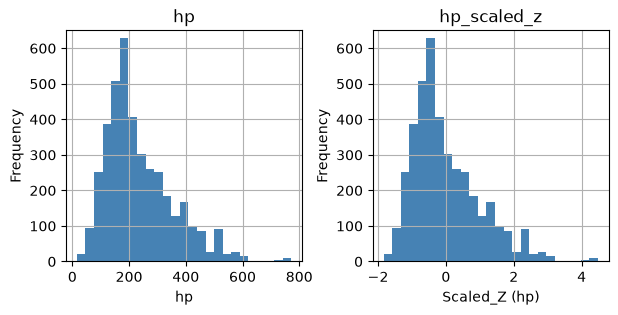

hp                   16.000000
hp_scaled_minmax      0.000000
hp_scaled_max_abs     0.020725
hp_scaled_robust     -1.205128
hp_scaled_z          -1.836956
dtype: float64

hp                   772.000000
hp_scaled_minmax       1.000000
hp_scaled_max_abs      1.000000
hp_scaled_robust       3.641026
hp_scaled_z            4.480344
dtype: float64

np.float64(119.6713884499283)

np.float64(156.0)

In [22]:
# Z-score Normalization of the variable 'hp'
df['hp_scaled_z'] = (df['hp'] - df['hp'].mean()) / df['hp'].std()

# Histogram of the variable 'hp' and 'hp_scaled_z'
ax = df[['hp', 'hp_scaled_z']].hist(bins=25, 
                                        figsize=(7, 3), 
                                        color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['hp', 'Scaled_Z (hp)']):
    axis.set_ylim(0, 650)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

display(df[['hp', 'hp_scaled_minmax', 'hp_scaled_max_abs', 'hp_scaled_robust','hp_scaled_z']].min())
display(df[['hp', 'hp_scaled_minmax', 'hp_scaled_max_abs', 'hp_scaled_robust','hp_scaled_z']].max())

display(df['hp'].std())
display(df['hp'].quantile(0.75) - df['hp'].quantile(0.25))

## Transformation

### Log-Transformation

np.float64(160.0)

np.True_

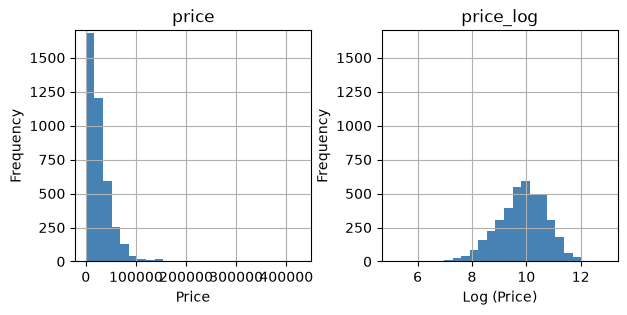

np.float64(22026.465794806718)

In [23]:
# check if 'price' contains 0
# 0 in df['price'].values -> nicht ideal, da negative Werte nicht berücksichtigt werden.

display(df['price'].min())            # kleinster Wert anschauen
display((df['price'] > 0).all())      # True, wenn alle Werte positiv sind

# Log-Transformation of the variable 'price'
df['price_log'] = np.log(df['price'])

# Histogram of the variable 'price' and 'price_log'
ax = df[['price', 'price_log']].hist(bins=25, 
                                   figsize=(7, 3), 
                                   color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Price', 'Log (Price)']):
    axis.set_ylim(0, 1700)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

display(np.exp(10))

np.exp(10) ≈ CHF 22'000 passt gut zum Median-Preis von rund CHF 19'900. Der Gipfel im Log-Histogramm liegt also tatsächlich beim „typischen“ Auto.

Der Ausläufer nach links bedeutet: Der Log hat etwas zu stark gedämpft. Aus einer rechtsschiefen Verteilung ist eine leicht linksschiefe geworden. Die billigsten Autos (ab CHF 160, log ≈ 5.1) werden jetzt weit nach links gezogen.

### SQRT-Transformation

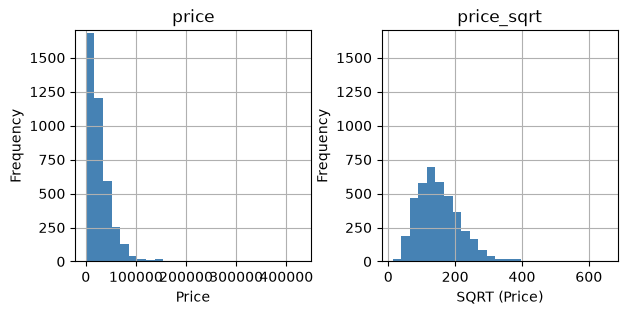

In [24]:
# SQRT-Transformation of the variable 'price'
df['price_sqrt'] = np.sqrt(df['price'])

# Histogram of the variable 'price' and 'price_sqrt'
ax = df[['price', 'price_sqrt']].hist(bins=25, 
                                    figsize=(7, 3), 
                                    color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Price', 'SQRT (Price)']):
    axis.set_ylim(0, 1700)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

### Box-Cox Transformation

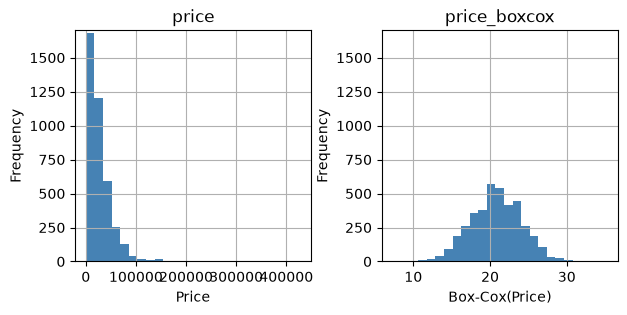

0.13497728850095814


np.float64(0.005283862061989992)

np.float64(1.1384537644288548)

np.float64(-0.3915797228817203)

In [25]:
# Box-Cox Transformation of the variable 'price'
from scipy.stats import boxcox

# Apply Box-Cox transformation
df['price_boxcox'], lam = boxcox(df['price'])

# Histogram of the variable 'price' and 'price_boxcox'
ax = df[['price', 'price_boxcox']].hist(bins=25, 
                                      figsize=(7, 3), 
                                      color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Price', 'Box-Cox(Price)']):
    axis.set_ylim(0, 1700)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()
print(lam)

display(df['price_boxcox'].skew())
display(df['price_sqrt'].skew())
display(df['price_log'].skew())

## Combining & organizing data

### Reading car data with geocoded addresses

In [26]:
# Geocoded data (i.e. data with latitude and longitude)
df_geo = pd.read_csv('./Data/autoscout24_data_geocoded.csv', 
                     sep=';', 
                     encoding='utf-8')

# Show data
df_geo.head()


,offer_id,lat,lon,bfs_number,bfs_name
0,7324420,47.434376,8.859333,228,Turbenthal
1,7512768,46.850327,7.200491,2293,Düdingen
2,7512034,46.386593,6.204862,5716,Eysins
3,7512728,47.542408,7.873130,4263,Zeiningen
4,7490242,47.067474,7.302120,306,Lyss


### Join geo-information to car data using .merge()

In [27]:
df2 = df.merge(df_geo[['offer_id', 
                       'lat', 
                       'lon', 
                       'bfs_number', 
                       'bfs_name']],
                how='left', 
                on="offer_id",
                indicator=True)

# Show data
display(df2[['offer_id',
     'scrape_dt',
     'type',
     'luxury_car',
     'price',
     'price_per_hp',
     'hp',
     'dealer_plz',
     'dealer_city',
     'dealer_street_house_nr',
     'lat', 
     'lon', 
     'bfs_number', 
     'bfs_name',
     '_merge']].head())

df2['_merge'].value_counts()

,offer_id,scrape_dt,type,luxury_car,price,price_per_hp,hp,dealer_plz,dealer_city,dealer_street_house_nr,lat,lon,bfs_number,bfs_name,_merge
0,7324420,2020_03_17 07:34:45,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,0,22500.0,91.84,245.0,8488,Turbenthal,Mettlenstrasse 3,47.434376,8.859333,228.0,Turbenthal,both
1,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),0,23749.0,129.07,184.0,3186,Düdingen,Brugerastrasse 60,46.850327,7.200491,2293.0,Düdingen,both
2,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,0,18500.0,60.46,306.0,1262,Eysins,1262 Eysins,46.386593,6.204862,5716.0,Eysins,both
3,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,0,36000.0,100.00,360.0,4314,Zeiningen,Am Stutz 21,47.542408,7.873130,4263.0,Zeiningen,both
4,7490242,2020_03_17 07:35:16,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,0,48500.0,192.46,252.0,3250,Lyss,3250 Lyss,47.067474,7.302120,306.0,Lyss,both


_merge
both          3538
left_only      433
right_only       0
Name: count, dtype: int64

In [28]:
# Check which rows do not match with geo data

display(len(df))
display(len(df2))

merge_left_only = df2['_merge'] == 'left_only'

df2_left_only = df2[merge_left_only]

df2_left_only.head()

3971

3971

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,...,hp_scaled_robust,hp_scaled_z,price_log,price_sqrt,price_boxcox,lat,lon,bfs_number,bfs_name,_merge
18,https://www.autoscout24.ch/7328315,7328315,2020_03_17 08:09:09,BMW X3 XDRIVE 20D (SUV / GELÄNDEWAGEN),CHF 19'900.–,184 PS,11.2013,137'000 km,Diesel,Automat,...,-0.128205,-0.433111,9.898475,141.067360,20.774321,NaN,NaN,NaN,NaN,left_only
19,https://www.autoscout24.ch/7510896,7510896,2020_03_17 08:11:57,DS AUTOMOBILES DS3 CABRIO 1.6 THP SPORT CHIC (...,CHF 8'800.–,156 PS,3.2013,67'000 km,Benzin,Schaltgetriebe manuell,...,-0.307692,-0.667085,9.082507,93.808315,17.835155,NaN,NaN,NaN,NaN,left_only
29,https://www.autoscout24.ch/7510203,7510203,2020_03_17 08:33:13,FIAT 500 1.2 LOUNGE (KLEINWAGEN),CHF 7'500.–,70 PS,4.2015,33'622 km,Benzin,Schaltgetriebe manuell,...,-0.858974,-1.385720,8.922658,86.602540,17.296329,NaN,NaN,NaN,NaN,left_only
34,https://www.autoscout24.ch/7510017,7510017,2020_03_17 08:34:40,SEAT LEON 2.0 TSI WORLD CHAMPION EDITION (LIMO...,CHF 13'000.–,285 PS,6.2009,130'000 km,Benzin,Schaltgetriebe manuell,...,0.519231,0.410867,9.472705,114.017543,19.200326,NaN,NaN,NaN,NaN,left_only
41,https://www.autoscout24.ch/7509947,7509947,2020_03_17 08:35:23,SEAT TOLEDO 1.4 TSI STYLE DSG (LIMOUSINE),CHF 8'450.–,122 PS,3.2013,119'000 km,Benzin,Automatisiertes Schaltgetriebe,...,-0.525641,-0.951197,9.041922,91.923882,17.697245,NaN,NaN,NaN,NaN,left_only


### Reading municipality-level data from an .xlsx - file

In [29]:
df_municip = pd.read_excel('./Data/municipality_data.xlsx', 
                           sheet_name='data_for_import')
df_municip.head(5)

,bfs_number,bfs_name,pop,pop_dens,frg_pct,emp
0,1,Aeugst am Albis,1981,250.442478,14.184755,442.0
1,2,Affoltern am Albis,12303,1161.756374,28.700317,6920.0
2,3,Bonstetten,5572,749.932705,16.564968,1014.0
3,4,Hausen am Albis,3751,275.808824,16.022394,1021.0
4,5,Hedingen,3778,578.560490,16.410799,1478.0


### Join municipality-level data to the car data data using .merge()

In [30]:
# Merge needs a key which must be identical in both data sets (here the key is 'bfs_number')
df3 = df2.merge(df_municip[['bfs_number', 
                            'pop', 
                            'pop_dens', 
                            'frg_pct', 
                            'emp']], 
                how='left',
                on="bfs_number",
                indicator='municip_merge')

# Show data
display(df3[['offer_id',
     'scrape_dt',
     'type',
     'luxury_car',
     'price',
     'price_per_hp',
     'hp',
     'dealer_plz',
     'dealer_city',
     'dealer_street_house_nr',
     'lat', 
     'lon', 
     'bfs_number', 
     'bfs_name',
     'pop',
     'pop_dens',
     '_merge']].head())

display(df3['_merge'].value_counts())
display(df3['municip_merge'].value_counts())

,offer_id,scrape_dt,type,luxury_car,price,price_per_hp,hp,dealer_plz,dealer_city,dealer_street_house_nr,lat,lon,bfs_number,bfs_name,pop,pop_dens,_merge
0,7324420,2020_03_17 07:34:45,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,0,22500.0,91.84,245.0,8488,Turbenthal,Mettlenstrasse 3,47.434376,8.859333,228.0,Turbenthal,4883.0,193.616178,both
1,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),0,23749.0,129.07,184.0,3186,Düdingen,Brugerastrasse 60,46.850327,7.200491,2293.0,Düdingen,8181.0,265.962289,both
2,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,0,18500.0,60.46,306.0,1262,Eysins,1262 Eysins,46.386593,6.204862,5716.0,Eysins,1735.0,728.991597,both
3,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,0,36000.0,100.00,360.0,4314,Zeiningen,Am Stutz 21,47.542408,7.873130,4263.0,Zeiningen,2381.0,209.410730,both
4,7490242,2020_03_17 07:35:16,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,0,48500.0,192.46,252.0,3250,Lyss,3250 Lyss,47.067474,7.302120,306.0,Lyss,15525.0,1046.864464,both


_merge
both          3538
left_only      433
right_only       0
Name: count, dtype: int64

municip_merge
both          3512
left_only      459
right_only       0
Name: count, dtype: int64

### Sorting data

In [31]:
# Sorting data by 'price' and 'hp' with highest price above (ascending=False)
df3 = df3.sort_values(by=['price', 'hp'], 
                ascending=False)

# Show data
display(df3[['offer_id',
     'scrape_dt',
     'type',
     'luxury_car',
     'price',
     'price_per_hp',
     'hp',
     'dealer_plz',
     'dealer_city',
     'dealer_street_house_nr',
     'lat', 
     'lon', 
     'bfs_number', 
     'bfs_name',
     'pop',
     'pop_dens']].head())

,offer_id,scrape_dt,type,luxury_car,price,price_per_hp,hp,dealer_plz,dealer_city,dealer_street_house_nr,lat,lon,bfs_number,bfs_name,pop,pop_dens
1621,6395032,2020_03_04 12:30:21,PORSCHE 911 GT2 RS (COUPÉ),1,428000.0,690.32,620.0,1628,Vuadens,Route principale 144,46.618042,7.024349,2160.0,Vuadens,2435.0,233.014354
312,6978696,2020_03_02 13:28:33,LAMBORGHINI AVENTADOR S LP740-4 ROADSTER E-GEA...,1,384900.0,519.43,741.0,8008,Zürich,8008 Zürich,47.354149,8.560637,261.0,Zürich,420217.0,4778.994655
2714,7448261,2020_03_10 11:50:05,PORSCHE 911 SPEEDSTER MANUAL GEARBOX CHALK WHI...,1,379000.0,743.14,510.0,1004,Lausanne,.,46.533829,6.611891,5586.0,Lausanne,139408.0,3368.970517
3876,6768872,2020_03_17 00:57:10,MCLAREN 675LT COUPÉ 3.8 V8 SSG (COUPÉ),1,280000.0,414.81,675.0,1202,Geneve,1202 Geneve,46.220200,6.145626,6621.0,Genève,203951.0,12810.992462
1824,5887777,2020_03_05 04:27:35,MERCEDES-BENZ 220 SE (CABRIOLET),0,255000.0,2125.00,120.0,6052,Hergiswil,Sonnenbergstrasse 9,46.992401,8.310424,1507.0,Hergiswil (NW),5776.0,403.916084


### Reshaping data

#### Reshaping data using .stack() and .unstack()

In [32]:
df_sub = df3[['bfs_name', 'type', 'price', 'hp']][:5]
print('Original shape')
print(df_sub, '\n')

df_sub_stacked = df_sub.stack()
print('Stacked')
print(df_sub_stacked, '\n')

# Using unstack
print('Unstacked (= back to original shape)')
print(df_sub_stacked.unstack())

Original shape
            bfs_name                                               type  \
1621         Vuadens                         PORSCHE 911 GT2 RS (COUPÉ)   
312           Zürich  LAMBORGHINI AVENTADOR S LP740-4 ROADSTER E-GEA...   
2714        Lausanne  PORSCHE 911 SPEEDSTER MANUAL GEARBOX CHALK WHI...   
3876          Genève             MCLAREN 675LT COUPÉ 3.8 V8 SSG (COUPÉ)   
1824  Hergiswil (NW)                   MERCEDES-BENZ 220 SE (CABRIOLET)   

         price     hp  
1621  428000.0  620.0  
312   384900.0  741.0  
2714  379000.0  510.0  
3876  280000.0  675.0  
1824  255000.0  120.0   

Stacked
1621  bfs_name                                              Vuadens
      type                               PORSCHE 911 GT2 RS (COUPÉ)
      price                                                428000.0
      hp                                                      620.0
312   bfs_name                                               Zürich
      type        LAMBORGHINI AVENTADOR 

#### Reshaping data using .melt()

In [33]:
df_sub = df3[['type', 'price', 'hp']][:5]
print('Original shape')
print(df_sub, '\n')

print('Reshaped using .melt()')
print(pd.melt(df_sub, id_vars=['type'], value_vars=['price', 'hp']))

Original shape
                                                   type     price     hp
1621                         PORSCHE 911 GT2 RS (COUPÉ)  428000.0  620.0
312   LAMBORGHINI AVENTADOR S LP740-4 ROADSTER E-GEA...  384900.0  741.0
2714  PORSCHE 911 SPEEDSTER MANUAL GEARBOX CHALK WHI...  379000.0  510.0
3876             MCLAREN 675LT COUPÉ 3.8 V8 SSG (COUPÉ)  280000.0  675.0
1824                   MERCEDES-BENZ 220 SE (CABRIOLET)  255000.0  120.0 

Reshaped using .melt()
                                                type variable     value
0                         PORSCHE 911 GT2 RS (COUPÉ)    price  428000.0
1  LAMBORGHINI AVENTADOR S LP740-4 ROADSTER E-GEA...    price  384900.0
2  PORSCHE 911 SPEEDSTER MANUAL GEARBOX CHALK WHI...    price  379000.0
3             MCLAREN 675LT COUPÉ 3.8 V8 SSG (COUPÉ)    price  280000.0
4                   MERCEDES-BENZ 220 SE (CABRIOLET)    price  255000.0
5                         PORSCHE 911 GT2 RS (COUPÉ)       hp     620.0
6  LAMBORGHINI AVE

### Pivoting data using .pivot_table()

In [34]:
# count the unique variales of df3
df3.nunique()

url_short                          3971
offer_id                           3971
scrape_dt                          3971
type                               2722
price_raw                           927
hp_raw                              345
init_regist                         458
mileage_raw                        1261
fuel_type                            17
transmission                         11
dealer_name                           1
dealer_plz                         1447
dealer_city                        1684
dealer_street_house_nr             3595
dealer_telnr                          1
init_regist_my                      458
init_regist_month                    12
init_regist_year                     73
init_regist_dt                      458
mileage                            1261
hp                                  345
price                               927
type_len                             78
luxury_car                            2
price_per_hp                       3067


In [35]:
pivot_table = pd.pivot_table(df3[['fuel_type', 'price', 'hp', 'price_per_hp']],
                             index=['fuel_type'],
                             values=['price','price_per_hp','hp'],
                             aggfunc={'price': ['count', 'mean'], 
                                     'price_per_hp': 'mean', 
                                     'hp': 'mean'}).round(2)

# Format the values to 2 decimal places with trailing zeros
pivot_table = pivot_table.map(lambda x: f"{x:.2f}" if isinstance(x, (int, float)) else x)

# Display the pivot table
pivot_table

hp    price           price_per_hp
                                 mean    count      mean         mean
fuel_type                                                            
Automat                        304.00     1.00  49000.00       161.18
Automatik-Getriebe             258.00     1.00  79999.00       310.07
Benzin                         247.91  2648.00  27889.74       112.76
Diesel                         197.28  1175.00  24976.57       124.88
Elektro                        446.57    67.00  51967.18       140.08
Erdgas (CNG) / Benzin           85.00     1.00   5900.00        69.41
Flüssiggas (LPG) / Benzin       97.00     1.00   4800.00        49.48
Hybrid Benzin/Elektro          339.00     1.00  19900.00        58.70
Hybrid Diesel/Elektro          261.00     1.00  34000.00       130.27
Mild-Hybrid Benzin/Elektro     269.67     3.00  60130.00       229.64
Mild-Hybrid Diesel/Elektro     340.00     2.00  82250.00       241.02
Plug-in-Hybrid Benzin/Elektro  278.69    26.00  40159.62       145.22
Plug-in-Hybrid Diesel/Elektro  286.00     4.00  28622.50       100.05
Schaltgetriebe                 242.67     3.00  28383.33        93.96
Schaltgetriebe manuell         125.00     1.00  31900.00       255.20
Voll-Hybrid Benzin/Elektro     168.48    31.00  23470.65       137.01
Voll-Hybrid Diesel/Elektro     200.20     5.00  17837.40        88.63

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [36]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-11-08 17:01:09
Python Version: 3.11.18
-----------------------------------
